<a href="https://colab.research.google.com/github/zhiyuguo-innis/MSSP607/blob/main/WeeklyModules/Week11/PARTICIPATION_ACTIVITY_Week_11_Plotting_geospatial_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PARTICIPATION ACTIVITY: Week 11 Plotting geospatial data.
**MSSP 607 · Zhiyu Guo**

Tasks:
1. Visualize California's congressional districts from the GeoJSON file.
2. Overlay the population data (`CA_Legislative_Districts.csv`) on the congressional districts.
3. Make a visualization of the districts that includes a heatmap of the state.

In [1]:
# Colab already has geopandas, folium and matplotlib; mapclassify is needed for classified choropleths
!pip install -q mapclassify

In [2]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import folium
from folium.plugins import HeatMap

## 1. Load the data
Both files are read from the `data/` folder of my course GitHub repo. If that fails (for example, the files are not pushed yet), the cell falls back to a file upload.

In [3]:
BASE = "https://raw.githubusercontent.com/zhiyuguo-innis/MSSP607/main/data/"
GEO_FILE = "california-congressional-districts.geojson"
CSV_FILE = "CA_Legislative_Districts.csv"

try:
    districts = gpd.read_file(BASE + GEO_FILE)
    pop = pd.read_csv(BASE + CSV_FILE, dtype={"DISTRICT": str})
    print("Loaded from GitHub")
except Exception as e:
    print("GitHub load failed, upload the two files instead:", e)
    from google.colab import files
    files.upload()
    districts = gpd.read_file(GEO_FILE)
    pop = pd.read_csv(CSV_FILE, dtype={"DISTRICT": str})

print(districts.shape, districts.crs)
districts.head()

Loaded from GitHub
(53, 4) EPSG:4326


,Name,description,descriptio,geometry
0,01,None,,"MULTIPOLYGON (((-120.07192 41.99495, -120.0010..."
1,02,None,,"MULTIPOLYGON (((-123.69821 41.81719, -123.6967..."
2,03,None,,"MULTIPOLYGON (((-121.667 39.30511, -121.63015 ..."
3,04,None,,"MULTIPOLYGON (((-120.37731 37.61679, -120.3823..."
4,05,None,,"MULTIPOLYGON (((-122.16384 38.64288, -122.1659..."


In [4]:
pop.info()
pop[["DISTRICT", "NAME", "POPULATION", "AREA", "CVAP_19"]].head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 25 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   OBJECTID      52 non-null     int64  
 1   ID            52 non-null     int64  
 2   AREA          52 non-null     float64
 3   DISTRICT      52 non-null     object 
 4   MEMBERS       52 non-null     int64  
 5   NAME          52 non-null     object 
 6   POPULATION    52 non-null     int64  
 7   CVAP_19       52 non-null     int64  
 8   HSP_CVAP_1    52 non-null     int64  
 9   DOJ_NH_BLK    52 non-null     int64  
 10  DOJ_NH_ASN    52 non-null     int64  
 11  NH_WHT_CVA    52 non-null     int64  
 12  IDEAL_VALU    52 non-null     int64  
 13  DEVIATION     52 non-null     int64  
 14  F_DEVIATIO    52 non-null     int64  
 15  MULTIPLE_F    52 non-null     object 
 16  F_CVAP_19     52 non-null     float64
 17  F_HSP_CVAP    52 non-null     float64
 18  F_DOJ_NH_B    52 non-null     fl

,DISTRICT,NAME,POPULATION,AREA,CVAP_19
0,01,MTCAP,760066,27014.63,549203
1,10,STANI,760066,560.65,503249
2,11,COCO,760067,226.43,568460
3,12,SF,760065,141.25,510978
4,13,OKLND,760065,6346.92,393416


## 2. Plot the congressional districts
The GeoJSON is in WGS84 (lat/long). For a static map I reproject to **California Albers (EPSG:3310)**, an equal-area projection, so district shapes and areas are not distorted.

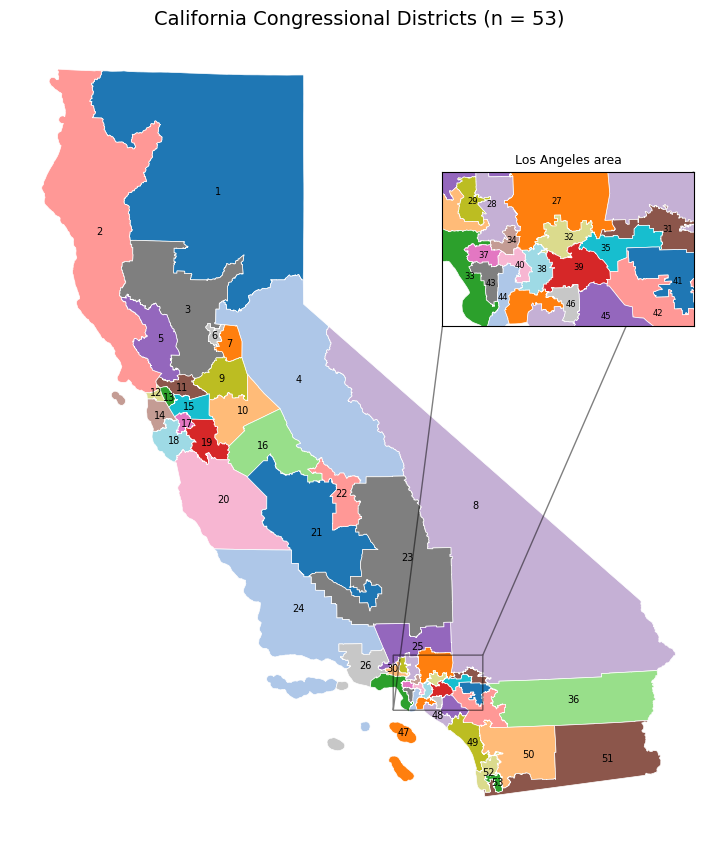

In [5]:
districts = districts.rename(columns={"Name": "DISTRICT"})[["DISTRICT", "geometry"]]
districts_ca = districts.to_crs(epsg=3310).sort_values("DISTRICT").reset_index(drop=True)

# 53 districts but only 20 colors in tab20, so cycle through the palette with a stride of 7
# so that consecutively numbered (often neighboring) districts get different colors
palette = plt.get_cmap("tab20").colors
districts_ca["color"] = [palette[(i * 7) % 20] for i in range(len(districts_ca))]

fig, ax = plt.subplots(figsize=(9, 11))
districts_ca.plot(ax=ax, color=districts_ca["color"], edgecolor="white", linewidth=0.5)

# inset zoom on Los Angeles, where districts are too small to read at state scale
axins = ax.inset_axes([0.62, 0.55, 0.36, 0.36])
districts_ca.plot(ax=axins, color=districts_ca["color"], edgecolor="white", linewidth=0.5)
axins.set_xlim(130_000, 260_000); axins.set_ylim(-480_000, -400_000)
axins.set_xticks([]); axins.set_yticks([]); axins.set_xlabel(""); axins.set_ylabel(""); axins.set_title("Los Angeles area", fontsize=9)
ax.indicate_inset_zoom(axins, edgecolor="black")
for _, row in districts_ca.iterrows():
    p = row.geometry.representative_point()
    if 130_000 < p.x < 260_000 and -480_000 < p.y < -400_000:
        axins.annotate(str(int(row.DISTRICT)), (p.x, p.y), ha="center", va="center", fontsize=6)

# label each district at a point guaranteed to be inside it
for _, row in districts_ca.iterrows():
    p = row.geometry.representative_point()
    in_la_box = 130_000 < p.x < 260_000 and -480_000 < p.y < -400_000
    if not in_la_box:   # LA districts are labeled in the inset instead
        ax.annotate(str(int(row.DISTRICT)), (p.x, p.y), ha="center", va="center", fontsize=7)

ax.set_title(f"California Congressional Districts (n = {len(districts_ca)})", fontsize=14)
ax.set_axis_off()
plt.show()

## 3. Join the population data to the districts
The CSV has no geometry, so it is joined to the shapes on the district number. The district codes are zero-padded strings in both files (`"01"`, `"02"`, ...).

**Check before joining:** the GeoJSON has **53** districts but the CSV has **52**.

In [6]:
print("GeoJSON districts:", districts.DISTRICT.nunique())
print("CSV districts:    ", pop.DISTRICT.nunique())
print("In GeoJSON but not in CSV:", sorted(set(districts.DISTRICT) - set(pop.DISTRICT)))
print("In CSV but not in GeoJSON:", sorted(set(pop.DISTRICT) - set(districts.DISTRICT)))

GeoJSON districts: 53
CSV districts:     52
In GeoJSON but not in CSV: ['53']
In CSV but not in GeoJSON: []


**Data caveat.** The GeoJSON is the **2011** congressional map (53 seats, used for the 2012–2020 elections). The CSV, with every district at about 760,066 people, is the **2021** redistricting (52 seats, after California lost a seat in the 2020 census). Districts with the same number do *not* cover the same area in the two maps, and district 53 has no match. I join on district number because that is what the assignment asks for, and check below which joined columns can be trusted on these shapes.

In [7]:
merged = districts_ca.drop(columns="color").merge(pop, on="DISTRICT", how="left")
print("Districts with no population data:", merged.loc[merged.POPULATION.isna(), "DISTRICT"].tolist())

merged[["POPULATION", "AREA"]].describe()

Districts with no population data: ['53']


,POPULATION,AREA
count,52.000000,52.000000
mean,760066.096154,3146.634231
std,0.773574,5876.293035
min,760065.000000,50.060000
25%,760065.750000,189.607500
50%,760066.000000,584.860000
75%,760067.000000,3596.647500
max,760067.000000,27014.630000


To confirm the boundaries differ, I compare each district's area computed from the GeoJSON polygons (EPSG:3310 is in meters, 1 sq mi = 2,589,988 m²) with the `AREA` column in the CSV. If the two files described the same districts, these would match.

In [8]:
merged["GEOM_AREA"] = merged.geometry.area / 2_589_988   # sq mi from the polygons

print("Correlation of GeoJSON area and CSV area:", round(merged[["GEOM_AREA", "AREA"]].corr().iloc[0, 1], 2))
merged.assign(ratio=merged.GEOM_AREA / merged.AREA)[["DISTRICT", "GEOM_AREA", "AREA", "ratio"]] \
      .sort_values("ratio", ascending=False).round(1).head(8)

Correlation of GeoJSON area and CSV area: 0.54


,DISTRICT,GEOM_AREA,AREA,ratio
7,08,33041.9,614.8,53.7
35,36,5990.3,194.7,30.8
50,51,5127.8,191.2,26.8
20,21,6743.7,893.3,7.5
49,50,2804.2,412.2,6.8
15,16,2885.3,713.2,4.0
3,04,13168.3,3923.9,3.4
9,10,1841.5,560.6,3.3


They do not match: district 8 is about 33,000 sq mi in the GeoJSON (the eastern desert) but about 600 sq mi in the CSV. So the CSV's `AREA` must not be used with these shapes.

What *can* be used is the CSV's `POPULATION`: districts are drawn to have equal population in every cycle, so every district, whichever map it belongs to, holds roughly the same number of people. Density for the GeoJSON districts is therefore **joined population ÷ polygon area**. District 53 has no CSV row, so I give it the CSV's ideal district population (`IDEAL_VALU` = 760,066).

## 4. Overlay population on the districts
Mapping raw population first:

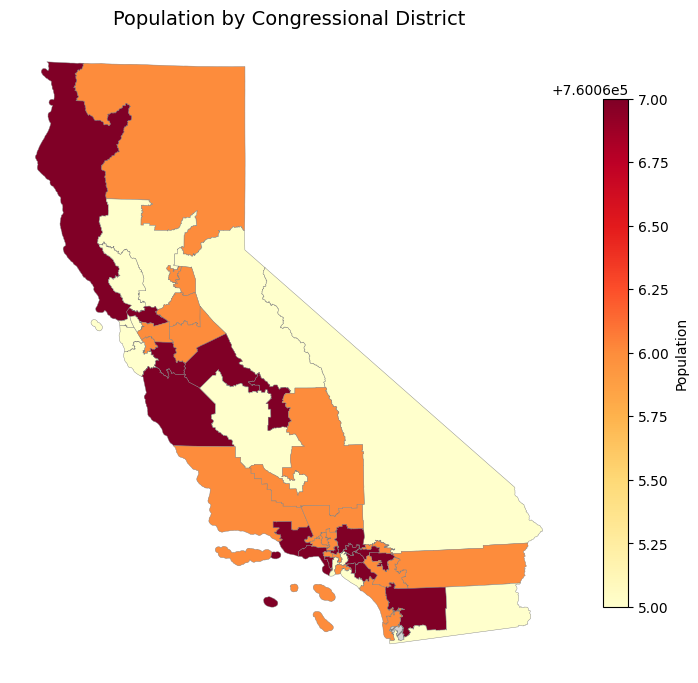

Population range: 760065.0 to 760067.0


In [9]:
fig, ax = plt.subplots(figsize=(9, 11))
merged.plot(ax=ax, column="POPULATION", cmap="YlOrRd", edgecolor="grey", linewidth=0.3,
            legend=True, legend_kwds={"label": "Population", "shrink": 0.6},
            missing_kwds={"color": "lightgrey", "hatch": "///", "label": "No data"})
ax.set_title("Population by Congressional District", fontsize=14)
ax.set_axis_off()
plt.show()

print("Population range:", merged.POPULATION.min(), "to", merged.POPULATION.max())

The map is almost a single color, and that is the finding: every district has 760,065 to 760,067 people. Congressional districts are drawn to have equal population ("one person, one vote"), so raw population cannot show where Californians live.

**Population density** (joined population ÷ polygon area) shows it. Density spans several orders of magnitude, so I use quantile classes rather than a linear scale.

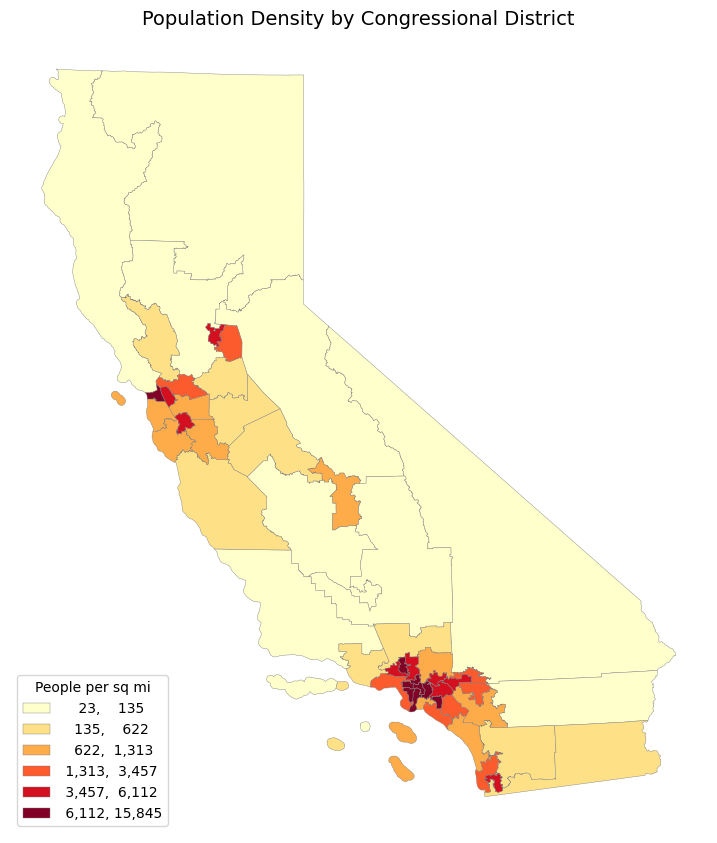

,DISTRICT,GEOM_AREA,DENSITY
33,34,48.0,15845.0
36,37,55.0,13721.0
39,40,58.0,13022.0
42,43,72.0,10520.0
45,46,73.0,10462.0


In [10]:
merged["POP_FILLED"] = merged["POPULATION"].fillna(pop["IDEAL_VALU"].iloc[0])
merged["DENSITY"] = merged["POP_FILLED"] / merged["GEOM_AREA"]   # people per sq mi

fig, ax = plt.subplots(figsize=(9, 11))
merged.plot(ax=ax, column="DENSITY", cmap="YlOrRd", scheme="Quantiles", k=6,
            edgecolor="grey", linewidth=0.3, legend=True,
            legend_kwds={"title": "People per sq mi", "loc": "lower left", "fmt": "{:,.0f}"},
            missing_kwds={"color": "lightgrey", "hatch": "///", "label": "No data"})
ax.set_title("Population Density by Congressional District", fontsize=14)
ax.set_axis_off()
plt.show()

merged.sort_values("DENSITY", ascending=False)[["DISTRICT", "GEOM_AREA", "DENSITY"]].round(0).head(5)

## 5. Interactive map: districts + heatmap of the state
A folium map with three layers that can be toggled in the top-right control:
- **District boundaries** with a tooltip for each district (number, population, area, density)
- **Heatmap** of where the population is concentrated: one point per district, weighted by density
- **Density choropleth** on a log10 scale (off by default so the heatmap is easy to read; tick it in the layer control)

Folium needs lat/long, so the data is converted back to EPSG:4326.

In [11]:
import numpy as np

m_df = merged.to_crs(epsg=4326)
m_df["LOG_DENSITY"] = np.log10(m_df["DENSITY"])
m_df["DENSITY"] = m_df["DENSITY"].round(0)
m_df["GEOM_AREA"] = m_df["GEOM_AREA"].round(0)

m = folium.Map(location=[37.2, -119.5], zoom_start=6, tiles="OpenStreetMap")

# layer 1: density choropleth (log10 so the legend is evenly spaced: 2 = 100, 3 = 1,000, 4 = 10,000 per sq mi)
folium.Choropleth(
    geo_data=m_df[["DISTRICT", "geometry"]].to_json(),
    data=m_df, columns=["DISTRICT", "LOG_DENSITY"], key_on="feature.properties.DISTRICT",
    fill_color="YlOrRd", fill_opacity=0.6, line_opacity=0.3,
    bins=[1, 2, 2.5, 3, 3.5, 4, 4.5],
    legend_name="log10 people per sq mi (3 = 1,000)",
    name="Density choropleth", show=False,
).add_to(m)

# layer 2: district outlines with tooltips
folium.GeoJson(
    m_df[["DISTRICT", "POP_FILLED", "GEOM_AREA", "DENSITY", "geometry"]].to_json(),
    name="District boundaries",
    style_function=lambda f: {"fillOpacity": 0, "color": "#333", "weight": 0.8},
    highlight_function=lambda f: {"weight": 3, "color": "black"},
    tooltip=folium.GeoJsonTooltip(
        fields=["DISTRICT", "POP_FILLED", "GEOM_AREA", "DENSITY"],
        aliases=["District", "Population", "Area (sq mi)", "People / sq mi"],
        localize=True),
).add_to(m)

# layer 3: heatmap of population concentration
pts = m_df.dropna(subset=["DENSITY"]).copy()
pts["pt"] = pts.to_crs(epsg=3310).geometry.representative_point().to_crs(epsg=4326)
heat_data = [[p.y, p.x, w] for p, w in zip(pts["pt"], pts["DENSITY"] / pts["DENSITY"].max())]
HeatMap(heat_data, name="Population heatmap", radius=30, blur=25, min_opacity=0.3).add_to(m)

folium.LayerControl(collapsed=False).add_to(m)
m

In [12]:
# optional: save the interactive map as a standalone HTML file
m.save("ca_congressional_districts_map.html")

## 6. Observations
- The 53-district GeoJSON draws districts as small as a few dozen square miles in Los Angeles and the Bay Area and as large as tens of thousands of square miles in the north and the eastern deserts.
- Raw population is flat across districts by design, so it is not useful for showing where people live; density is.
- The density map and heatmap show population concentrated in the Los Angeles basin, the Bay Area, San Diego and, less sharply, Sacramento, with the northern counties, the Sierra and the eastern deserts sparsely populated.
- Limitation: the population file and the GeoJSON come from different redistricting cycles (2021 vs 2011). Population still transfers well because districts are equal-population by law, but every other CSV column (area, CVAP, race/ethnicity shares) describes different territory and should not be mapped onto these shapes. With the 2021 district shapefile from the California Citizens Redistricting Commission, the same code would map those columns correctly.